# EN3160 Assignment 2 on Fitting and Alignment

##### Index No: 230476T
##### Name: Perera G.M.B.

https://github.com/maneth-b03p/Image_Processing_and_Machine_Vision_Activities.git

### Q1: Blob detection with Laplacian of Gaussians and scale-space extrema.

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

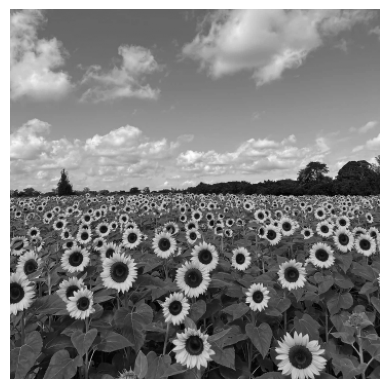

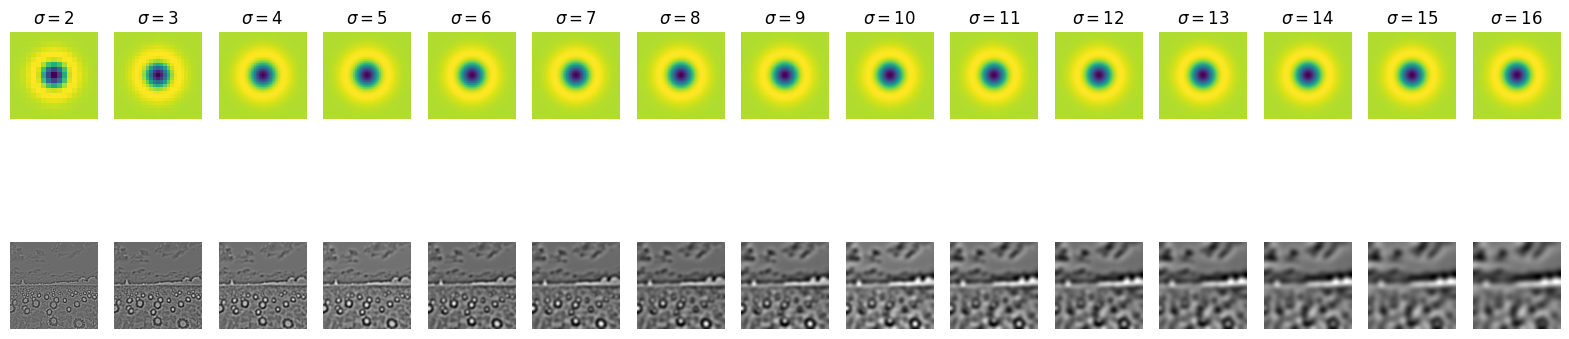

In [ ]:
image_rgb = cv.imread('a2images/a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
image = cv.cvtColor(image_rgb, cv.COLOR_BGR2GRAY)

#sigma = 15

# image_gaussian = cv.GaussianBlur(image, (0, 0), sigmaX = sigma)
# laplacian_signed = cv.Laplacian(image_gaussian, cv.CV_16S, ksize=1)*sigma**2

# print(laplacian_signed)

plt.imshow(image, cmap = "gray")
plt.axis("off")
plt.show()

h,w = image.shape
min_sig = 2
s = 15
fig, ax = plt.subplots(2, s, figsize=(20,5))
scale_space = np.empty((h, w, s), dtype=np.float32)
sigmas = np.arange(min_sig, min_sig+s , 1)
for i, sigma in enumerate(sigmas):
    log_hw = 4*np.max(sigma)
    X, Y = np.meshgrid(np.arange(-log_hw, log_hw + 1, 1), np.arange(-log_hw, log_hw + 1, 1))
    log = 1/(2*np.pi*sigma**2)*(X**2/(sigma**2) + Y**2/(sigma**2) - 2)*np.exp(-(X**2 + Y**2)/(2*sigma**2))
    f_log = cv.filter2D(image, cv.CV_32F, log)
    scale_space[:, :, i] = f_log
    ax[0, i].imshow(log)
    ax[0, i].axis('off')
    ax[0, i].set_title(r'$\sigma = {}$'.format(sigma))    
    ax[1, i].imshow(f_log, cmap = "gray")
    ax[1, i].axis('off')

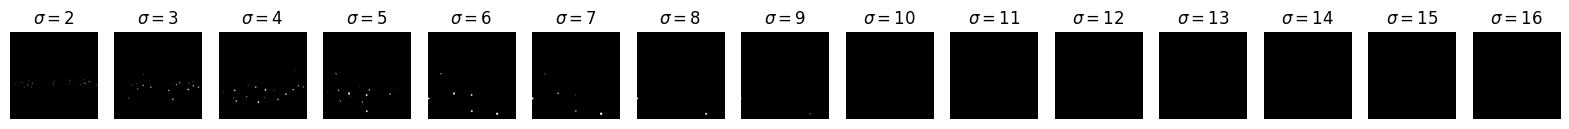

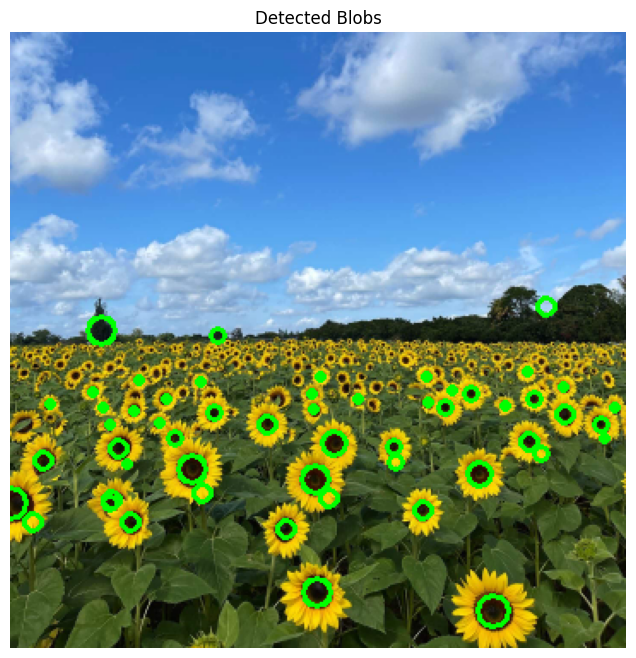

In [ ]:
fig, ax = plt.subplots(1, s, figsize=(20,5))

scale_space_abs = np.abs(scale_space)
threshold_value = 70.0
binary_scale_space = scale_space_abs > threshold_value

for i in range(s):
    ax[i].set_title(r'$\sigma = {}$'.format(sigmas[i]))    
    ax[i].imshow(binary_scale_space[:,:,i], cmap = "gray")
    ax[i].axis('off')

local_max = maximum_filter(scale_space_abs, size=(3, 3, 3))
is_extrema = (scale_space_abs == local_max) & (scale_space_abs > threshold_value)

x_indices, y_indices, sigma_indices = np.where(is_extrema)

output_image = image_rgb.copy()

for x, y, s_idx in zip(x_indices, y_indices, sigma_indices):
    matched_sigma = sigmas[s_idx]
    radius = int(np.sqrt(2) * matched_sigma)
    cv.circle(output_image, (y, x), radius, (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(output_image, cv.COLOR_BGR2RGB))
plt.title(f"Detected Blobs")
plt.axis("off")
plt.show()

In [ ]:
for i in range(s-1, -1, -1):
    if np.any(is_extrema[:, :, i]):
        found_layer_idx = i
        x_coords, y_coords = np.where(is_extrema[:, :, i])
        largest_scale_coordinates = list(zip(x_coords, y_coords))
        break
print(f"Center Coordinates of Largest Circles: {largest_scale_coordinates}")
print(f"Radius of the Largest Circle: {sigmas[i]*np.sqrt(2)} pixels")
print(f"Range of sigmas used: {sigmas}")

Center Coordinates of Largest Circles: [(275, 0), (338, 282)]
Radius of the Largest Circle: 9.899494936611665 pixels
Range of sigmas used: [ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]


The suitable gaussian kernel sizes and Threshold value of 70 are manually fine-tuned

### Question 2: Line and Circle Fitting with RANSAC

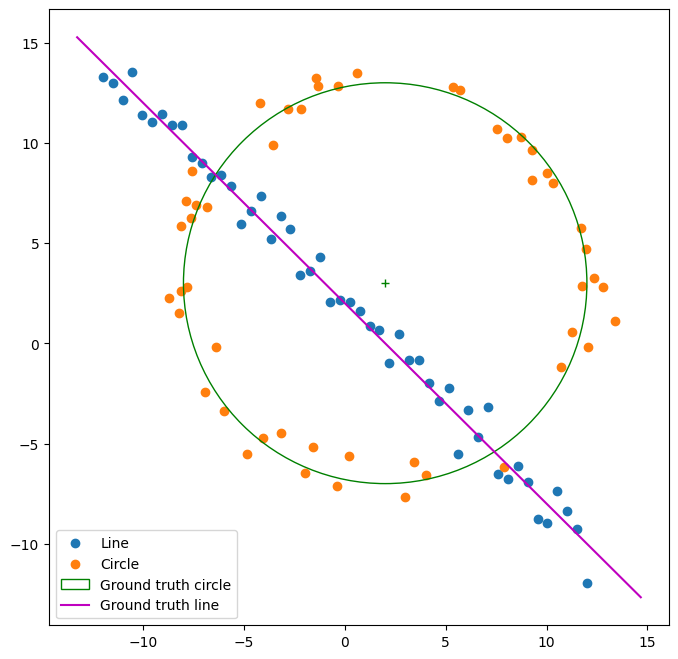

In [28]:
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
#import tikzplotlib

np.random.seed(476)
N = 100
half_n = N//2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

X = np.vstack((X_circ, X_line))

# All points
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')

circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()

In [50]:
e = 0.5 # outlier ratio
s = 2 # line fit
p = 0.99

N_sample = int(np.log(1-p)/np.log(1-(1-e)**s))+1

sigma = 0.6
t = 1.96*sigma



In [51]:
def fit_line(p1, p2):
    a = p1[1] - p2[1]
    b = p2[0] - p1[0]

    norm = np.sqrt(a**2 + b**2)
    if norm < 1e-10:
        return None
    a /= norm
    b /= norm
    d = -(a * p1[0] + b * p1[1])
    return a, b, d

def tls(points):
    centroid = np.mean(points, axis=0)
    centered = points - centroid

    _, _, Vt = np.linalg.svd(centered)

    a, b = Vt[-1]
    d = -(a * centroid[0] + b * centroid[1])

    return a, b, d


In [52]:
best_inliers = None
best_model = None
best_count = 0

for i in range(N_sample):

    indices = np.random.choice(len(X), size=2, replace=False)
    p1, p2 = X[indices]

    model = fit_line(p1, p2)
    a, b, d = model

    distances = np.abs(a * X[:, 0] + b * X[:, 1] + d)
    inliers = (distances < t)
    count = np.sum(inliers)

    if count > best_count:
        best_count = count
        best_inliers = inliers
        best_model = model

print("RANSAC iterations:", N_sample)
print("Best consensus size:", best_count)
print("Initial line (a, b, d):", best_model)

RANSAC iterations: 17
Best consensus size: 49
Initial line (a, b, d): (-0.6972344443586739, -0.716843169458879, 1.4793213912811853)


a = 0.7048, b = 0.7094, d = -1.4510


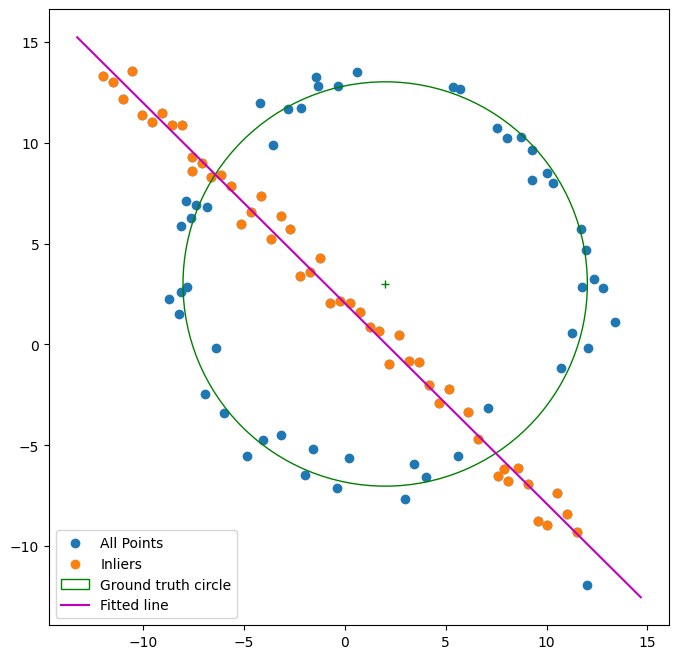

In [53]:
X_inliers = X[best_inliers]
a, b, d = tls(X_inliers)
print(f"a = {a:.4f}, b = {b:.4f}, d = {d:.4f}")

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X[:, 0], X[:, 1], label='All Points')
ax.scatter(X_inliers[:, 0], X_inliers[:, 1], label='Inliers')

circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = -(a*x_ + d)/b
plt.plot(x_, y_, color='m', label='Fitted line')
plt.legend()

In [ ]:
X_rem = X[~best_inliers]
N_new = len(X_rem)

e = 0.3 # outlier ratio
s = 3 # circle fit
p = 0.99

N_sample = int(np.log(1-p)/np.log(1-(1-e)**s))+1






In [55]:
def fit_circle(p1, p2, p3):
    A = 2 * np.array([
        [p2[0] - p1[0], p2[1] - p1[1]],
        [p3[0] - p1[0], p3[1] - p1[1]]
    ])

    B = np.array([
        p2[0]**2 + p2[1]**2 - p1[0]**2 - p1[1]**2,
        p3[0]**2 + p3[1]**2 - p1[0]**2 - p1[1]**2
    ])

    if abs(np.linalg.det(A)) < 1e-10:
        return None

    xc, yc = np.linalg.solve(A, B)
    r = np.sqrt((p1[0] - xc)**2 + (p1[1] - yc)**2)

    return xc, yc, r

In [60]:
best_circle = None
best_circle_inliers = None
best_circle_count = 0

for i in range(N_sample):
    indices = np.random.choice(len(X_rem), size=3, replace=False)
    p1, p2, p3 = X_rem[indices]

    circle = fit_circle(p1, p2, p3)
    xc, yc, r = circle

    radial_errors = np.abs(
        np.sqrt((X_rem[:, 0]-xc)**2 + (X_rem[:, 1]-yc)**2) - r
    )

    sigma = r/16
    t = 1.96*sigma


    inliers = (radial_errors < t)
    count = np.sum(inliers)

    if count > best_circle_count:
        best_circle_count = count
        best_circle_inliers = inliers
        best_circle = circle

print("RANSAC iterations:", N_sample)
print("Best circle consensus:", best_circle_count)
print("Initial circle (xc, yc, r):", best_circle)

RANSAC iterations: 11
Best circle consensus: 45
Initial circle (xc, yc, r): (1.8671800636692206, 3.5816879513606423, 9.835356096014864)


In [61]:
X_circle_inliers = X_rem[best_circle_inliers]

def cost_func(params, points):
    xc,yc,r = params
    distances = np.sqrt((points[:,0]-xc)**2 +(points[:,1]-yc)**2)
    errors = distances-r
    return np.sum(errors**2)

result = minimize(
    cost_func,
    x0=np.array(best_circle),
    args=(X_circle_inliers,),
    method='BFGS'
)

xc, yc, r = result.x

print("Refined circle:")
print(f"Center: ({xc:.4f}, {yc:.4f})")
print(f"Radius: {r:.4f}")

Refined circle:
Center: (1.8360, 3.3065)
Radius: 9.9308


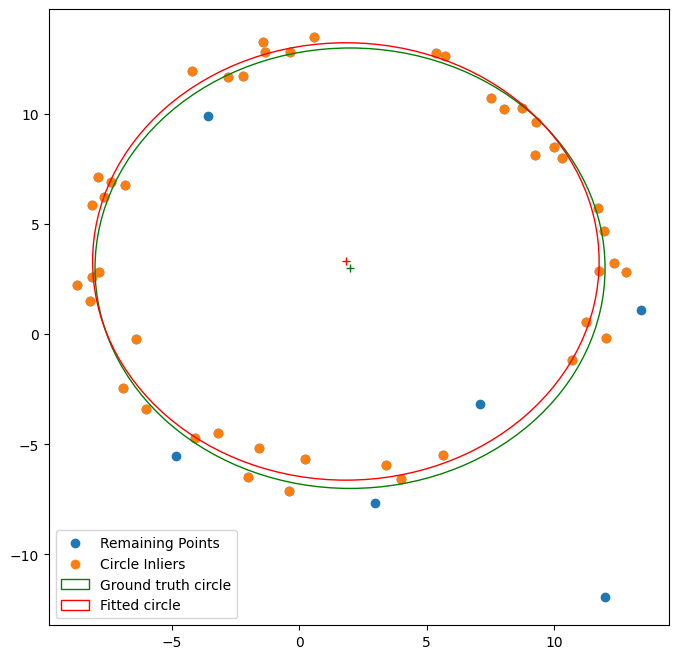

In [62]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.scatter(X_rem[:, 0], X_rem[:, 1], label='Remaining Points')
ax.scatter(X_circle_inliers[:, 0], X_circle_inliers[:, 1],
           label='Circle Inliers')

circle_gt = plt.Circle((x0_gt, y0_gt), 10,color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot(x0_gt, y0_gt, '+', color='g')

circle_fit = plt.Circle((xc, yc), r,color='r', fill=False, label='Fitted circle')
ax.add_patch(circle_fit)
ax.plot(xc, yc, '+', color='r')

plt.legend()
plt.show()

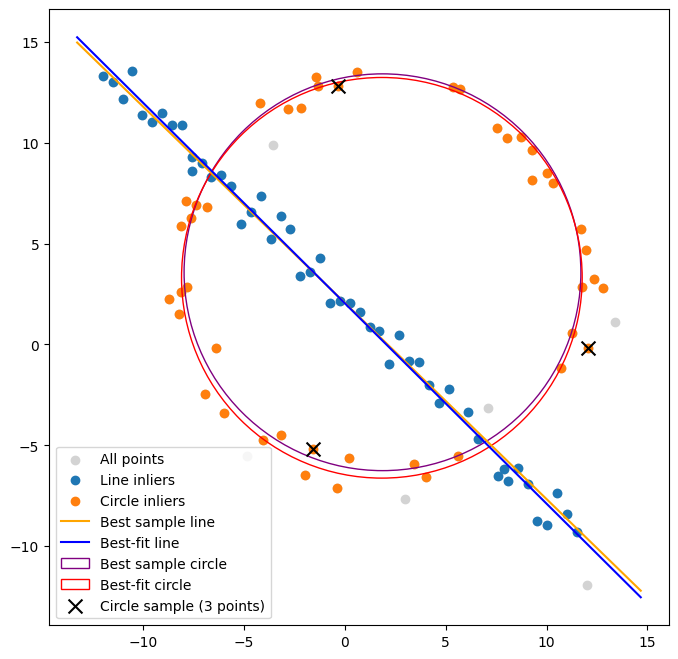

In [63]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.scatter(X[:, 0], X[:, 1], label='All points', color='lightgray')
ax.scatter(X[best_inliers, 0], X[best_inliers, 1], label='Line inliers')
ax.scatter(X_rem[best_circle_inliers, 0], X_rem[best_circle_inliers, 1], label='Circle inliers')

a_sample, b_sample, d_sample = best_model
x_ = np.array(ax.get_xlim())
ax.plot(x_, -(a_sample*x_ + d_sample)/b_sample, label='Best sample line', color='orange')
ax.plot(x_, -(a*x_ +d)/b, label='Best-fit line', color='blue')

xc_sample, yc_sample, r_sample = best_circle
ax.add_patch(plt.Circle((xc_sample, yc_sample), r_sample, fill=False, color='purple', label='Best sample circle'))
ax.add_patch(plt.Circle((xc, yc), r, fill=False, color='red', label='Best-fit circle'))

sample_points = np.array([p1, p2, p3])
ax.scatter(sample_points[:, 0], sample_points[:, 1], color='black', marker='x', s=100, label='Circle sample (3 points)')

ax.set_aspect('equal', adjustable='box')
ax.legend()
plt.show()

### Q3: Homography

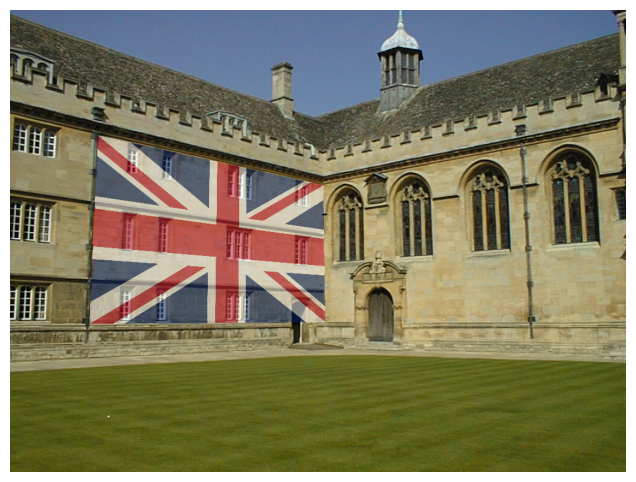

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_src = cv2.imread('a2images/a2images/flag.png')
img_dst = cv2.imread('a2images/a2images/wadham.jpg')

src_points = []
dst_points = []

def select_src_points(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(src_points) < 4:
        src_points.append([x, y])
        cv2.circle(img_src_temp, (x, y), 5, (0, 0, 255), -1)
        cv2.imshow('Source Image', img_src_temp)

def select_dst_points(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(dst_points) < 4:
        dst_points.append([x, y])
        cv2.circle(img_dst_temp, (x, y), 5, (0, 255, 0), -1)
        cv2.imshow('Destination Image', img_dst_temp)


img_src_temp = img_src.copy()
cv2.namedWindow('Source Image', cv2.WINDOW_NORMAL)

cv2.imshow('Source Image', img_src_temp)
cv2.setMouseCallback('Source Image', select_src_points)
cv2.waitKey(0)
cv2.destroyAllWindows()

img_dst_temp = img_dst.copy()
cv2.imshow('Destination Image', img_dst_temp)
cv2.setMouseCallback('Destination Image', select_dst_points)
cv2.waitKey(0)
cv2.destroyAllWindows()


if len(src_points) == 4 and len(dst_points) == 4:
    pts_src = np.array(src_points, dtype=np.float32)
    pts_dst = np.array(dst_points, dtype=np.float32)

    H, status = cv2.findHomography(pts_src, pts_dst)

    h, w, c = img_dst.shape
    warped_img = cv2.warpPerspective(img_src, H, (w, h))

    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.fillConvexPoly(mask, np.int32(pts_dst), 255)

    mask_inv = cv2.bitwise_not(mask)
    img_dst_bg = cv2.bitwise_and(img_dst, img_dst, mask=mask_inv)
    warped_fg = cv2.bitwise_and(warped_img, warped_img, mask=mask)

    a = 0.5

    blended = cv2.addWeighted(img_dst,1-a, warped_fg, a, 0)
    result = cv2.add(img_dst_bg, cv2.bitwise_and(blended, blended, mask=mask))

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()
else:
    print("Error")

### Q4: PCB Image Alignment

(2730, 2302, 3)
(2729, 2279, 3)


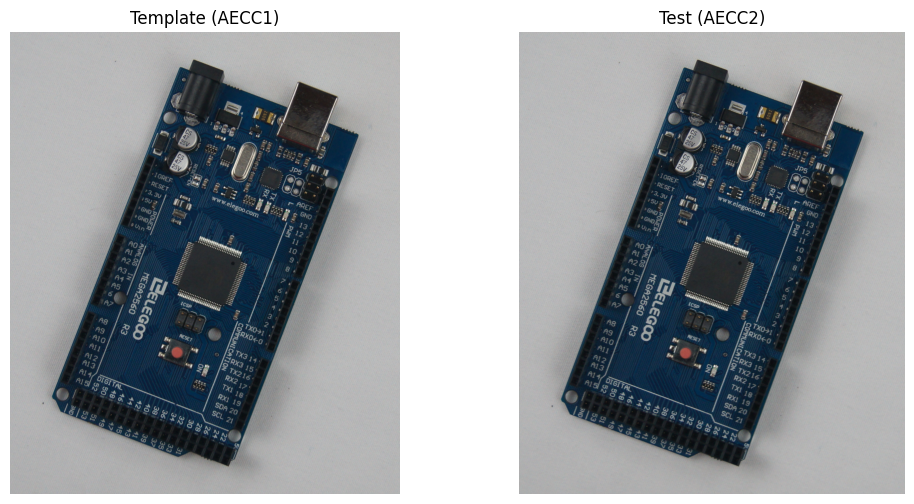

In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_template = cv2.imread('a2images/a2images/pcbs/AECC1.jpg')
img_test = cv2.imread('a2images/a2images/pcbs/AECC2.jpg')

print(img_template.shape)
print(img_test.shape)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_template, cv2.COLOR_BGR2RGB))
plt.title('Template (AECC1)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_test, cv2.COLOR_BGR2RGB))
plt.title('Test (AECC2)')
plt.axis('off')
plt.show()

Template keypoints: 14272
Test keypoints: 12315
Descriptor shape (template): (14272, 128)
Descriptor shape (test): (12315, 128)


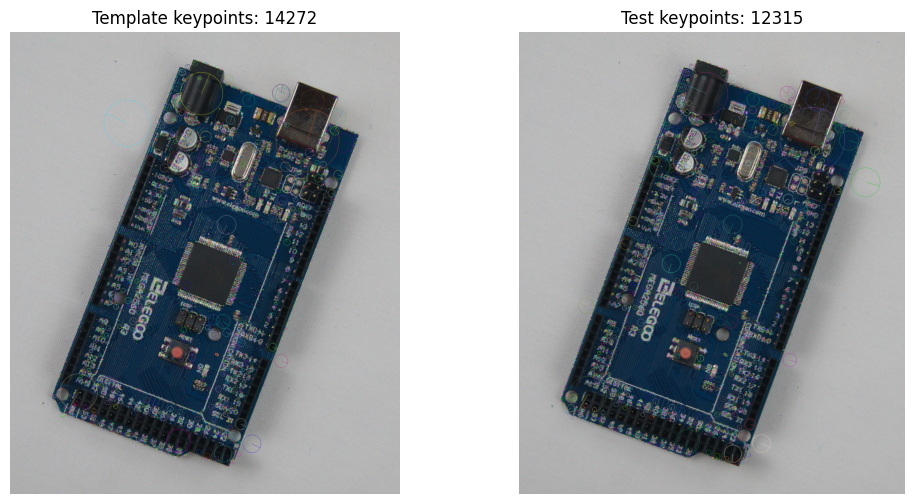

In [34]:
sift = cv2.SIFT_create()

kp_template, des_template = sift.detectAndCompute(img_template, None)
kp_test, des_test = sift.detectAndCompute(img_test, None)

print('Template keypoints:', len(kp_template))
print('Test keypoints:', len(kp_test))
print('Descriptor shape (template):', des_template.shape)
print('Descriptor shape (test):', des_test.shape)

img_kp_template = cv2.drawKeypoints(img_template, kp_template, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
img_kp_test     = cv2.drawKeypoints(img_test, kp_test, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_kp_template, cv2.COLOR_BGR2RGB))
plt.title(f'Template keypoints: {len(kp_template)}')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_kp_test, cv2.COLOR_BGR2RGB))
plt.title(f'Test keypoints: {len(kp_test)}')
plt.axis('off')
plt.show()


In [41]:
bf = cv2.BFMatcher(cv2.NORM_L2)

raw_matches = bf.knnMatch(des_test, des_template, k=2)
good_matches = []
for m, n in raw_matches:
    if m.distance < 0.8 * n.distance:
        good_matches.append(m)


print('Raw matches:', len(raw_matches))
print('Good matches after ratio test:', len(good_matches))

Raw matches: 12315
Good matches after ratio test: 4929


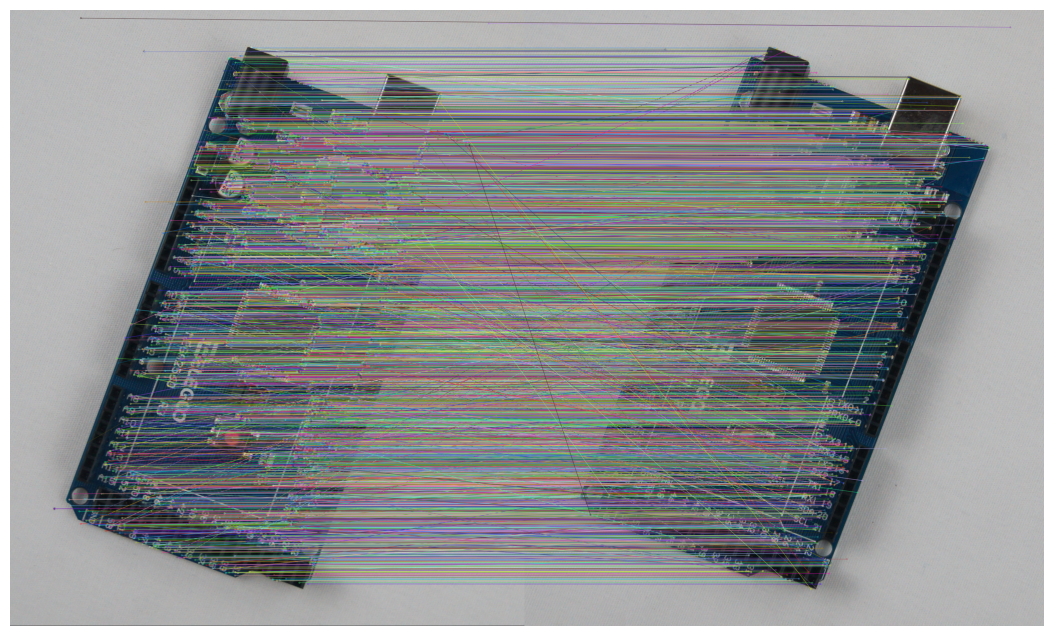

In [42]:
matched_img = cv2.drawMatches(
    img_test, 
    kp_test,
    img_template, 
    kp_template,
    good_matches, 
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [44]:
src_pts = np.float32([kp_test[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp_template[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

H, mask_inliers = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)

inliers = int(mask_inliers.sum())
print('RANSAC inliers:', inliers)
print('Homography H:\n', H)

RANSAC inliers: 4118
Homography H:
 [[ 1.00054383e+00 -1.50243163e-02  3.21089951e+01]
 [ 1.65309389e-02  1.00003139e+00 -1.81380684e+01]
 [ 3.17563197e-07  2.69313098e-07  1.00000000e+00]]
